# 01 · Exploring the data

This notebook looks at the two datasets the way I would before building any model: how big they are, what the cleaning removes, how outcomes differ between groups, and which features travel with the sensitive attributes. Only aggregate statistics are printed, never individual student rows.

It uses the real UCI files if `make data` has been run, and otherwise falls back to the synthetic copies (the first cell tells you which).

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "font.size": 10})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
from fairpath.data import load_dataset
from fairpath.config import load_settings
s = load_settings()
data = {name: load_dataset(name, s) for name in ["dropout", "student_mat"]}
for name, ds in data.items():
    print(f"{name:12s} source={ds.source:9s} n={len(ds.y):5d}  at-risk={ds.y.mean():.1%}  features={ds.X.shape[1]}")
    for note in ds.notes: print("   -", note[:110])

dropout      source=real      n= 3630  at-risk=39.1%  features=24
   - Removed 794 rows with Target in ['Enrolled'].
   - Dropped 12 leakage columns: Curricular units 1st sem (credited), Curricular units 1st sem (enrolled), Curricul
student_mat  source=real      n=  395  at-risk=32.9%  features=30
   - Dropped 2 leakage columns: G1, G2.


## What the cleaning removes, and why it matters

The dropout file has twelve end-of-semester columns. A quick model with and without them shows why the thesis drops them: with them, the model is mostly reading the answer off the student's own transcript.

In [2]:
from fairpath.data.loaders import read_raw, resolve_path
from fairpath.config import load_dataset_spec
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import HistGradientBoostingClassifier
spec = load_dataset_spec("dropout")
raw = read_raw(spec, resolve_path(spec, s)[0])
raw = raw[raw.Target != "Enrolled"]
y = (raw.Target == "Dropout").astype(int)
leaky = raw.drop(columns=["Target"])
clean = leaky.drop(columns=[c for c in leaky.columns if c.startswith("Curricular units")])
for label, X in [("with curricular units (leaky)", leaky), ("without (what FairPath uses)", clean)]:
    auc = cross_val_score(HistGradientBoostingClassifier(random_state=0), X, y, cv=5, scoring="roc_auc").mean()
    print(f"{label:32s} AUC = {auc:.3f}")

with curricular units (leaky)    AUC = 0.955


without (what FairPath uses)     AUC = 0.844


## Outcomes by group

Base rates differ a lot on the dropout data (men drop out far more often) and only a little on the school data. That difference in signal strength is the starting point of the thesis.

In [3]:
rows = []
for name, ds in data.items():
    for axis, spec_s in ds.spec.sensitive.items():
        g = ds.sensitive[axis].astype(str)
        for level, block in pd.Series(ds.y).groupby(g.values):
            rows.append({"dataset": name, "axis": spec_s.label, "group": spec_s.groups.get(int(level) if level.isdigit() else level, level),
                         "n": len(block), "at-risk rate": block.mean()})
tab = pd.DataFrame(rows)
tab

,dataset,axis,group,n,at-risk rate
0,dropout,Gender,Female,2381,0.302
1,dropout,Gender,Male,1249,0.561
2,dropout,Debtor status,Not a debtor,3217,0.345
3,dropout,Debtor status,Debtor,413,0.755
4,dropout,Age at enrolment,20 or younger,2080,0.261
5,dropout,Age at enrolment,21-25,646,0.457
6,dropout,Age at enrolment,Over 25,904,0.646
7,student_mat,Sex,Female,208,0.361
8,student_mat,Sex,Male,187,0.294
9,student_mat,Home address,Rural,88,0.375


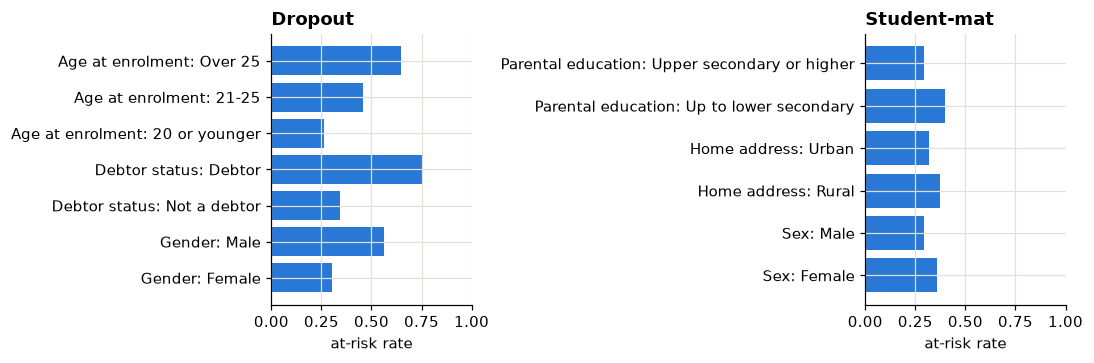

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, (name, ds) in zip(axes, data.items()):
    t = tab[tab.dataset == name]
    labels = t.axis + ": " + t.group.astype(str)
    ax.barh(labels, t["at-risk rate"], color=BLUE)
    ax.set_title(ds.spec.short_title, loc="left", fontweight="bold"); ax.set_xlim(0, 1); ax.set_xlabel("at-risk rate")
plt.tight_layout()

## Which features travel with the sensitive attribute?

If a feature differs a lot between groups *and* predicts the outcome, it can carry group information into a model even when the sensitive column is removed. Here I measure the first part with a simple standardised difference (numeric features) or the largest difference in category share (categorical ones).

In [5]:
def proxy_strength(ds, axis):
    g = ds.sensitive[axis].astype(str).values
    a, b = sorted(set(g))[:2]
    out = []
    for f in ds.spec.features:
        if f.name == axis: continue
        col = ds.X[f.name]
        if f.type == "categorical":
            share = pd.crosstab(col, g, normalize="columns")
            d = float((share[a] - share[b]).abs().max())
        else:
            x = col.astype(float); sd = x.std() or 1
            d = float(abs(x[g == a].mean() - x[g == b].mean()) / sd)
        out.append({"feature": f.label, "difference between groups": d})
    return pd.DataFrame(out).sort_values("difference between groups", ascending=False).head(8)
proxy_strength(data["dropout"], "gender")

,feature,difference between groups
19,Scholarship holder,0.396
7,Age at enrolment,0.379
11,Studying away from home,0.269
17,Tuition fees up to date,0.257
2,Choice rank of this programme,0.223
1,Application route,0.132
0,Programme,0.127
6,Previous qualification grade,0.121


In [6]:
proxy_strength(data["student_mat"], "sex")

,feature,difference between groups
18,Weekly study time,0.613
28,Weekend alcohol use,0.548
27,Weekday alcohol use,0.536
25,Free time after school,0.478
3,Self-rated health,0.287
7,Mother's education,0.156
26,Going out with friends,0.152
13,Family educational support,0.148


Programme choice, application route, age and finances differ by gender on the dropout data. Those are exactly the paths through which a 'gender-blind' model can still produce gender gaps, which is what the fairness study later confirms.

## Is the synthetic copy faithful enough to develop against?

In [7]:
from fairpath.data import load_dataset
for name in ["dropout", "student_mat"]:
    real = data[name]
    if real.is_synthetic:
        print("real data not available, skipping comparison"); break
    syn = load_dataset(name, s, source="synthetic")
    num = [f.name for f in real.spec.features if f.type == "numeric"][:6]
    comp = pd.DataFrame({"real mean": real.X[num].mean(), "synthetic mean": syn.X[num].mean(),
                         "real sd": real.X[num].std(), "synthetic sd": syn.X[num].std()})
    print(f"\n{name}: at-risk rate real {real.y.mean():.3f} vs synthetic {syn.y.mean():.3f}")
    display(comp)


dropout: at-risk rate real 0.391 vs synthetic 0.407


,real mean,synthetic mean,real sd,synthetic sd
application_order,1.750,1.761,1.334,1.365
admission_grade,127.294,127.594,14.611,14.720
previous_qualification_grade,132.921,132.954,13.238,13.441
age_at_enrollment,23.461,23.436,7.828,7.780
unemployment_rate,11.630,11.651,2.668,2.682
inflation_rate,1.232,1.208,1.385,1.383



student_mat: at-risk rate real 0.329 vs synthetic 0.294


,real mean,synthetic mean,real sd,synthetic sd
age,16.696,16.691,1.276,1.236
health,3.554,3.663,1.390,1.318
Medu,2.749,2.767,1.095,1.125
Fedu,2.522,2.597,1.088,1.093
famrel,3.944,3.937,0.897,0.903
traveltime,1.448,1.461,0.698,0.680
